# Baseline Model: Logistic Regression on TF-IDF

This notebook builds and evaluates our baseline model, a Logistic Regression classifier trained on TF-IDF features extracted from article text. As an inherently interpretable model, it serves as both a performance reference point and a transparent benchmark for comparing against more complex models in later notebooks.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score
)

from preprocessing import (
    preprocess_text, get_tfidf_features,
    get_train_test_split, select_top_k_terms, get_split_tfidf, RANDOM_STATE
)

import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv.gz")
df[["title", "text", "label", "label_encoded"]].head()

,title,text,label,label_encoded
0,BREAKING: GOP Chairman Grassley Has Had Enough...,"Donald Trump s White House is in chaos, and th...",fake,1
1,Failed GOP Candidates Remembered In Hilarious ...,Now that Donald Trump is the presumptive GOP n...,fake,1
2,Mike Pence’s New DC Neighbors Are HILARIOUSLY ...,Mike Pence is a huge homophobe. He supports ex...,fake,1
3,California AG pledges to defend birth control ...,California Attorney General Xavier Becerra sai...,real,0
4,AZ RANCHERS Living On US-Mexico Border Destroy...,Twisted reasoning is all that comes from Pelos...,fake,1


## 3. Text Preprocessing (NLP Pipeline)

Combine `title` + `text`, then apply: lowercasing → punctuation/special character removal → tokenization → stopword removal → lemmatization.

In [3]:
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
df[["full_text", "processed_text"]].head()

,full_text,processed_text
0,BREAKING: GOP Chairman Grassley Has Had Enough...,breaking gop chairman grassley enough demand t...
1,Failed GOP Candidates Remembered In Hilarious ...,failed gop candidate remembered hilarious mock...
2,Mike Pence’s New DC Neighbors Are HILARIOUSLY ...,mike penny new dc neighbor hilariously trollin...
3,California AG pledges to defend birth control ...,california ag pledge defend birth control insu...
4,AZ RANCHERS Living On US-Mexico Border Destroy...,az rancher living u mexico border destroy nanc...


In [4]:
print("RAW:\n", df["full_text"].iloc[0][:300])
print("\nPROCESSED:\n", df["processed_text"].iloc[0][:300])

RAW:
 BREAKING: GOP Chairman Grassley Has Had Enough, DEMANDS Trump Jr. Testimony Donald Trump s White House is in chaos, and they are trying to cover it up. Their Russia problems are mounting by the hour, and they refuse to acknowledge that there are problems surrounding all of this. To them, it s  fake 

PROCESSED:
 breaking gop chairman grassley enough demand trump jr testimony donald trump white house chaos trying cover russia problem mounting hour refuse acknowledge problem surrounding fake news hoax however fact bear thing differently seems crack congressional public leadership chuck grassley r iowa head se


## 4. TF-IDF Vectorization (Unigrams)

In [5]:
X, y, tfidf = get_tfidf_features(df)
print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (38633, 5000)


The vocabulary reaches the 5,000-term cap set in `get_tfidf_features()`. Real news text has a much larger vocabulary than this, so the cap decides which terms are kept: the 5,000 most frequent ones.

## 5. Train/Test Split

Fixed `random_state` and `stratify=y` ensure this exact split is reused identically across every model in this project.

In [6]:
X_train, X_test, y_train, y_test, tfidf = get_split_tfidf(df)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))

Train shape: (30906, 5000)
Test shape: (7727, 5000)

Train class balance:
 label_encoded
0    0.549
1    0.451
Name: proportion, dtype: float64

Test class balance:
 label_encoded
0    0.548
1    0.452
Name: proportion, dtype: float64


## 6. Train Baseline Model: Logistic Regression

In [7]:
log_reg = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)

## 7. Evaluation

Recall on the **Fake** class (`label_encoded = 1`) is the primary metric, per the project's trust-and-safety framing.

In [8]:
print(classification_report(y_test, y_pred, target_names=["real", "fake"]))

recall_fake = recall_score(y_test, y_pred, pos_label=1)
print(f"Recall on Fake class (primary metric): {recall_fake:.4f}")

              precision    recall  f1-score   support

        real       0.97      0.99      0.98      4238
        fake       0.99      0.97      0.98      3489

    accuracy                           0.98      7727
   macro avg       0.98      0.98      0.98      7727
weighted avg       0.98      0.98      0.98      7727

Recall on Fake class (primary metric): 0.9690


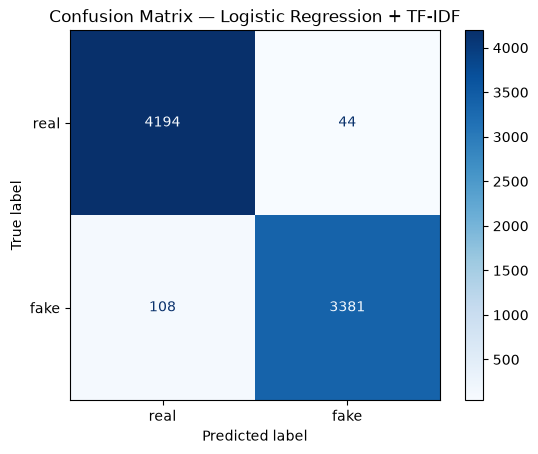

In [9]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["real", "fake"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix — Logistic Regression + TF-IDF")
plt.show()

- True Positive, correctly caught fake news article: 3,381
- False Negative, fake news article predicted as real: 108
- False Positive, real article predicted as fake: 44
- True Negative, correctly identified real article: 4,194

The model catches 96.9% of fake articles (recall = 0.9690), and 98.7% of its "fake" flags are correct (precision = 0.987). Overall accuracy is 98.0%.

For context, the test set is 45.2% fake, so a model that labels everything as real would get 54.8% accuracy and catch no fake articles at all. The baseline is far above this.

For a trust-and-safety reviewer, 108 fake articles out of 3,489 slip through (about 1 in 32), and only 44 real articles are wrongly flagged. Missing fakes is about 2.5 times as common as false alarms, so if catching fakes matters most, the decision threshold could be lowered below 0.5 at the cost of more false alarms.

### 7.1 Sanity Check: Is the Signal Real?

A score this high should be checked before it is trusted. We compare the model against (1) a dummy model that always predicts the majority class, "real," and (2) the same logistic regression trained on **shuffled labels**, where any real link between text and label is destroyed on purpose.

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import permutation_test_score, StratifiedKFold

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Dummy (always 'real') accuracy: {dummy.score(X_test, y_test):.4f}")

score, perm_scores, p_value = permutation_test_score(
    LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
    X_train, y_train, scoring="accuracy",
    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    n_permutations=100, random_state=RANDOM_STATE, n_jobs=-1
)
print(f"CV accuracy (real labels):     {score:.4f}")
print(f"CV accuracy (shuffled labels): {perm_scores.mean():.4f}")
print(f"p-value: {p_value:.3f}")

Dummy (always 'real') accuracy: 0.5485
CV accuracy (real labels):     0.9798
CV accuracy (shuffled labels): 0.5178
p-value: 0.010


Cross-validated accuracy on the real labels is 0.9797, close to the test score (0.980), so the result does not depend on one lucky split. On shuffled labels it falls to 0.518, around the share of the majority class, and the dummy gets 0.549. The p-value of 0.010 is the smallest possible with 100 permutations: not one of the 100 shuffled runs came close to the real score.

So the text does carry a strong fake/real signal. A high score alone does not tell us what that signal is, though. It could be the content and style of the articles, or fingerprints of the two sources, which Section 8 checks.

## 8. Interpretability: Coefficients → Odds Ratios

Since logistic regression is inherently interpretable, no post-hoc explanation method is needed. Coefficients map directly to specific words/n-grams.

In [11]:
feature_names = tfidf.get_feature_names_out()
coefficients = log_reg.coef_[0]

coef_df = pd.DataFrame({
    "term": feature_names,
    "coefficient": coefficients,
    "odds_ratio": np.exp(coefficients)
})

print("Top 15 terms pushing toward FAKE (label_encoded=1):")
display(coef_df.sort_values("coefficient", ascending=False).head(15))

print("\nTop 15 terms pushing toward REAL (label_encoded=0):")
display(coef_df.sort_values("coefficient", ascending=True).head(15))

Top 15 terms pushing toward FAKE (label_encoded=1):


,term,coefficient,odds_ratio
4789,via,11.746906,126361.960552
4793,video,9.042008,8450.732839
2206,image,8.814214,6729.217529
3605,read,7.044788,1146.865336
1943,gop,6.464373,641.861895
1705,featured,6.220526,502.967664
2100,hillary,5.319659,204.314165
4927,wire,5.106205,165.042822
4862,watch,5.051424,156.244777
857,com,4.984244,146.093055



Top 15 terms pushing toward REAL (label_encoded=0):


,term,coefficient,odds_ratio
3905,said,-16.939279,4.399108e-08
3801,reuters,-6.549358,1.431033e-03
4881,wednesday,-5.956984,2.587705e-03
4655,tuesday,-5.709576,3.314077e-03
4536,thursday,-5.359082,4.705225e-03
1856,friday,-4.834402,7.951438e-03
3414,presidential,-4.324845,1.323560e-02
2891,monday,-4.081319,1.688518e-02
3740,representative,-4.003434,1.825284e-02
3041,nov,-3.947160,1.930947e-02


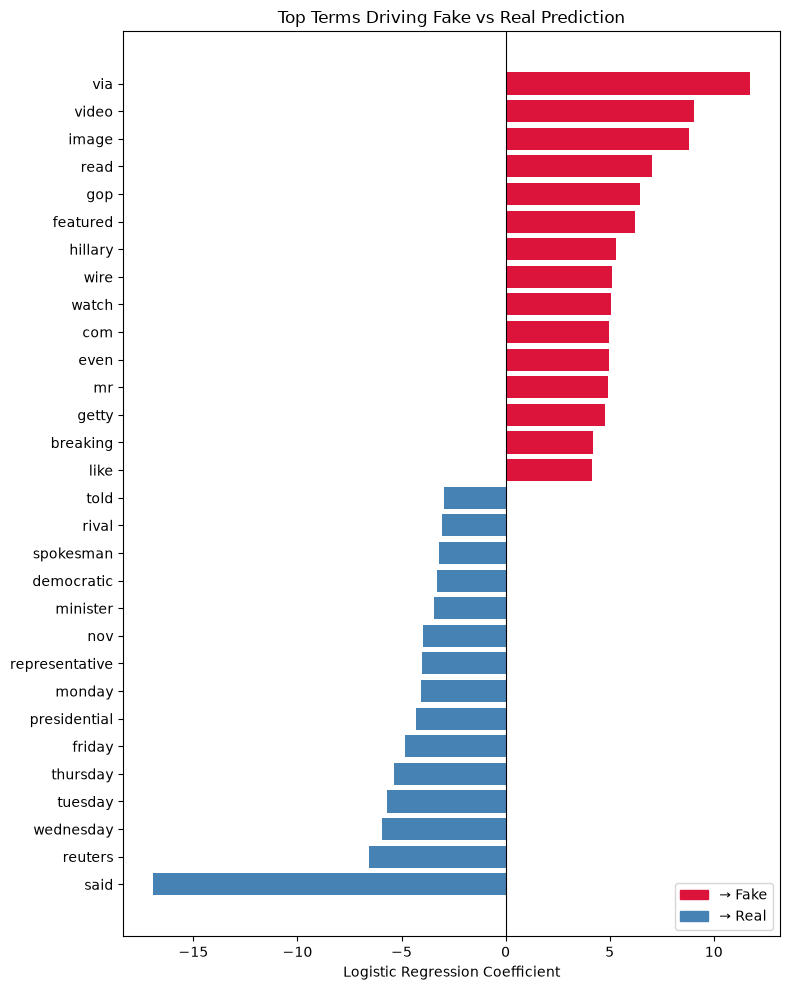

In [12]:
top_n = 15
top_fake = coef_df.nlargest(top_n, "coefficient")   # positive → pushes toward FAKE (1)
top_real = coef_df.nsmallest(top_n, "coefficient")  # negative → pushes toward REAL (0)
plot_df = pd.concat([top_real, top_fake]).sort_values("coefficient")

plt.figure(figsize=(8, 10))
colors = ["crimson" if c > 0 else "steelblue" for c in plot_df["coefficient"]]
plt.barh(plot_df["term"], plot_df["coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)

from matplotlib.patches import Patch
plt.legend(handles=[Patch(color="crimson", label="→ Fake"),
                    Patch(color="steelblue", label="→ Real")], loc="lower right")
plt.title("Top Terms Driving Fake vs Real Prediction")
plt.xlabel("Logistic Regression Coefficient")
plt.tight_layout()
plt.show()

The top terms fall into three groups:

- **Source fingerprints.** via, image, featured and getty come from photo credits on fake sites ("Featured image via Getty Images"), com from links, wire from site sign-offs ("21st Century Wire"), and read from "READ MORE" links. On the real side, reuters still appears in article bodies ("told Reuters") after the dateline was removed. These identify where an article was scraped from, not what it says.
- **Reuters house style.** said is by far the strongest term overall (coefficient −16.9), followed by the weekdays (wednesday, tuesday, thursday, friday, monday), nov, told and spokesman. Wire reports attribute every claim ("said on Tuesday") and abbreviate months. Formal terms like presidential, representative and minister point the same way.
- **Fake-site style.** gop and hillary (Reuters writes "Republican" and "Clinton"), mr ("Mr. Trump" appears mostly in fake articles), breaking, video, watch, even and like: headline-style, partisan and conversational language.

Note on odds ratios: an odds ratio is the change in odds for a 1.0 increase in a term's TF-IDF weight. Real weights are far below 1 (when said appears, its median weight is about 0.05), so odds ratios like 126,518 for via are meaningless as written. Coefficient × typical weight gives a better sense of size: said moves a typical article by about −0.9 in log-odds, and via by about +0.35. The coefficients are best read as a ranking of which terms the model relies on.

### 8.1 Does the Model Depend on Source Fingerprints?

Several top terms are fingerprints of where an article was scraped rather than what it says: photo credits (via, image, featured, getty), links (com, http, www, pic, twitter), site sign-offs (wire, read) and the word reuters. If the model's accuracy came mainly from these, it would be detecting the source, not the content. To test this, we retrain the same model with these terms removed.

In [13]:
from sklearn.metrics import accuracy_score

fingerprints = ["reuters", "via", "image", "images", "featured", "getty",
                "com", "http", "www", "pic", "twitter", "wire", "read", "video", "watch"]
present = [t for t in fingerprints if t in tfidf.vocabulary_]
keep = np.array([i for t, i in sorted(tfidf.vocabulary_.items(), key=lambda kv: kv[1]) if t not in present])

log_reg_nofp = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
log_reg_nofp.fit(X_train[:, keep], y_train)
y_pred_nofp = log_reg_nofp.predict(X_test[:, keep])

print("Terms removed:", present)
print(f"\nAccuracy    with all terms: {accuracy_score(y_test, y_pred):.4f}   without fingerprints: {accuracy_score(y_test, y_pred_nofp):.4f}")
print(f"Fake recall with all terms: {recall_fake:.4f}   without fingerprints: {recall_score(y_test, y_pred_nofp, pos_label=1):.4f}")

Terms removed: ['reuters', 'via', 'image', 'featured', 'getty', 'com', 'http', 'www', 'pic', 'twitter', 'wire', 'read', 'video', 'watch']

Accuracy    with all terms: 0.9803   without fingerprints: 0.9741
Fake recall with all terms: 0.9690   without fingerprints: 0.9616


Removing 14 fingerprint terms lowers accuracy only from 0.980 to 0.974 and fake recall from 0.969 to 0.962. The model does use the fingerprints, but they are not what makes it work. Without them, the top terms become gop, hillary, mr, breaking and america toward fake, and said, weekdays, presidential and told toward real: the style differences described above. This makes the baseline a fair reference for the later models, and the same question (source or style?) should be asked of each of them.

The top terms include shortcuts: photo credits, link fragments and the publisher's own name. The model uses them, so it is fair to ask how much of its 98% accuracy they explain. The check below answers that.

### Why No LIME/SHAP/PDP/ICE for Logistic Regression

Logistic regression is interpretable by design: each coefficient tells us exactly how a word shifts the log-odds of “fake,” with no approximation. This gives us the global explanation directly. For a single article, the explanation is just as direct: multiply each word’s coefficient by its TF-IDF weight in that article and add them up. That is exactly the model’s score.

Post-hoc tools like LIME, PDP, and ICE exist to probe black-box models from the outside, so they add little here. (SHAP on a linear model reduces to essentially the coefficient × feature calculation above.) These tools become necessary from the next tier onward (Random Forest, XGBoost, LightGBM, non-linear SVM), where the model’s internals no longer explain its predictions directly. A single shallow Decision Tree is the exception, since it can be read directly as well.

## Summary

This notebook set our baseline: a Logistic Regression on TF-IDF features. It reaches a Fake-class recall of 0.969, a precision of 0.987 and an accuracy of 0.980, against 0.548 for always predicting "real." Cross-validation (0.980) and the permutation test (p = 0.010, the minimum possible) confirm that the signal is real and not a lucky split.

The coefficients show what the signal is made of. Some of it is source fingerprints (via, image, featured, getty, reuters), but removing these lowers accuracy by only 0.6 points. Most of the signal is writing style: Reuters' attribution and date conventions (said, told, weekdays) against the partisan, headline-style language of fake sites (gop, hillary, breaking, mr).

This also means the model learned to tell Reuters from these particular fake sites, which is narrower than telling true from false. An honest article written in a casual style, or a fabricated one written like a wire report, could be misclassified. Every later model is compared against this baseline, both on scores and on whether it relies on style or on fingerprints.